In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import skops.io as sio

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, StandardScaler, OneHotEncoder

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    ConfusionMatrixDisplay,
    confusion_matrix
)


In [2]:
drug_df = pd.read_csv('Data/drug.csv')
drug_df = drug_df.sample(frac=1, random_state=125)
drug_df.head(3)

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
123,36,F,NORMAL,HIGH,16.753,DrugY
135,74,M,LOW,NORMAL,11.939,drugX
101,45,F,HIGH,HIGH,12.854,drugA


In [3]:
X = drug_df.drop("Drug", axis=1).values
y = drug_df.Drug.values

X = drug_df.drop("Drug", axis=1).to_numpy()
y = drug_df["Drug"].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=125
)

In [4]:
cat_col = [1, 2, 3]
num_col = [0, 4]

transform = ColumnTransformer(
    [
        ("encoder", OrdinalEncoder(), cat_col),
        ("num_imputer", SimpleImputer(strategy="median"), num_col),
        ("num_scaler", StandardScaler(), num_col),
    ]
)
pipe = Pipeline(
    steps=[
        ("preprocessing", transform),
        ("model", RandomForestClassifier(n_estimators=100, random_state=125)),
    ]
)
pipe.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('encoder', OrdinalEncoder(),
                                                  [1, 2, 3]),
                                                 ('num_imputer',
                                                  SimpleImputer(strategy='median'),
                                                  [0, 4]),
                                                 ('num_scaler',
                                                  StandardScaler(), [0, 4])])),
                ('model', RandomForestClassifier(random_state=125))])

In [5]:
predictions = pipe.predict(X_test)
accuracy = accuracy_score(y_test, predictions)
f1 = f1_score(y_test, predictions, average="macro")

print("Accuracy:", str(round(accuracy,2)*100)+ "%", "F1:", round(f1, 2))

Accuracy: 100.0% F1: 1.0


In [6]:
with open("Results/metrics.txt", "w") as outfile:
    outfile.write(f"Accuracy: {accuracy:.2%}\n")
    outfile.write(f"F1 Score: {f1:.2f}\n")

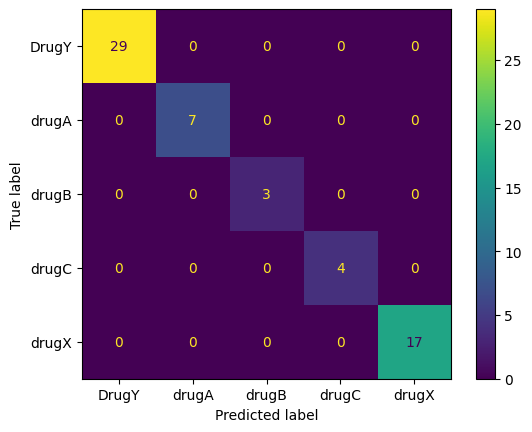

In [7]:
cm = confusion_matrix(y_test, predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=pipe.classes_)   
disp.plot()
plt.savefig("Results/confusion_matrix.png", dpi=120)

In [8]:
sio.dump(pipe, "Model/drug_pipeline.skops")

In [9]:
import skops.io as sio

# Get the untrusted types in the pipeline
untrusted_types = sio.get_untrusted_types(
    file="Model/drug_pipeline.skops"
)

# Display them for inspection
print("Untrusted types:", untrusted_types)

# Load the entire pipeline
pipe = sio.load(
    "Model/drug_pipeline.skops",
    trusted=untrusted_types
)

Untrusted types: ['numpy.dtype']
